# Atelier AI - Historical Training Dataset

Construct supervised examples for six chronological target weeks. Preserve full candidate and relevance populations, then form complete informative ranking groups for fitting. The exact validation export and cohort are shared with the preceding notebook.

## 1. Calendar and fixed cohort

One ranking group is one customer at one prediction cutoff. Its 300 articles compete within that group. Each cutoff receives its own historical retrieval and features; validation features are never copied into historical training examples.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown
import atelier_ai
from atelier_ai.temporal_protocol import load_protocol
from atelier_ai.notebook_tools import show_figure

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]
protocol = load_protocol(PROJECT_ROOT)

from atelier_ai.workflow import cohort, export_training
from atelier_ai.training_targets import make_training_schedule
customer_ids=cohort(PROJECT_ROOT)
schedule=make_training_schedule(validation_cutoff=protocol['validation_start'],n_weeks=protocol['training_weeks'])
assert len(schedule)==6
assert schedule['target_end'].le(protocol['validation_start']).all()
display(schedule)

,cutoff,history_start,popularity_start,target_end
0,2020-07-22,2020-01-24,2020-07-15,2020-07-29
1,2020-07-29,2020-01-31,2020-07-22,2020-08-05
2,2020-08-05,2020-02-07,2020-07-29,2020-08-12
3,2020-08-12,2020-02-14,2020-08-05,2020-08-19
4,2020-08-19,2020-02-21,2020-08-12,2020-08-26
5,2020-08-26,2020-02-28,2020-08-19,2020-09-02


## 2. Target windows

Training targets are six consecutive seven-day windows. Their 180-day histories precede their respective cutoff. The plotted bars show target weeks, rather than the longer feature-history windows.

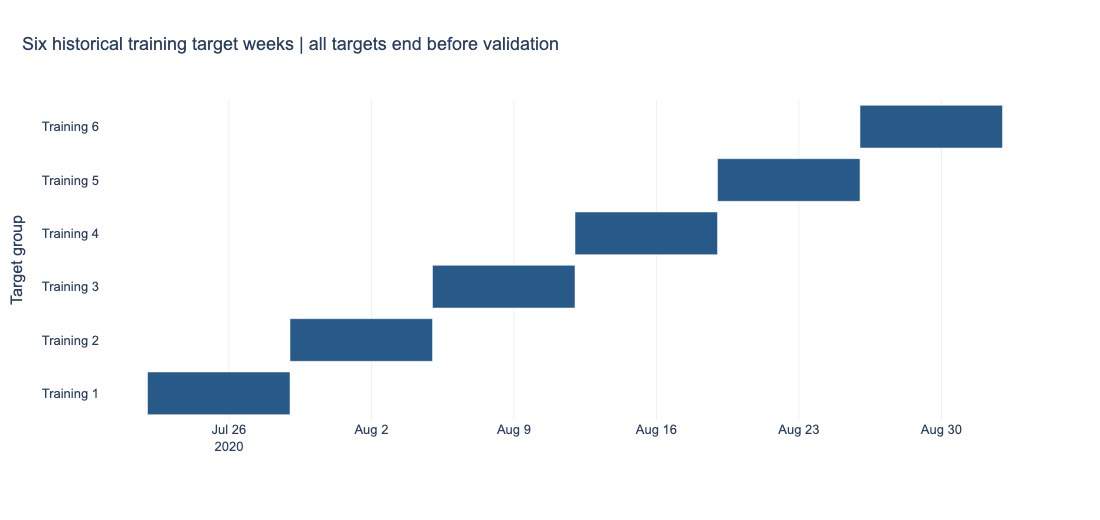

In [2]:
timeline=schedule[['cutoff','target_end']].rename(columns={'cutoff':'start','target_end':'end'})
timeline['period']=[f'Training {i+1}' for i in range(len(timeline))]
fig=px.timeline(timeline,x_start='start',x_end='end',y='period',
    title='Six historical training target weeks | all targets end before validation',
    labels={'period':'Target group','start':'Inclusive start','end':'Exclusive end'})
show_figure(fig,PROJECT_ROOT,'training_windows')

## 3. Retrieval, labels and export

For each cutoff, first generate candidates using earlier purchases. Then attach label 1 when the candidate is purchased during that target week, otherwise 0. A zero means no purchase observed in this horizon, not dislike.

Future purchases absent from the candidate set remain in reference targets and are not inserted into training candidates. The complete population contains 20,000 customers × six cutoffs × 300 candidates.

In [3]:
training_index,training_summary=export_training(PROJECT_ROOT)
assert training_index['raw_candidate_rows']==36_000_000
assert training_index['raw_groups']==120_000
display(training_summary)
display(pd.Series({k:v for k,v in training_index.items() if k not in ['exports','feature_columns']}))

Training cutoff 2020-07-22
Verified feature partitions: 5; customers: 2,500
Verified feature partitions: 10; customers: 5,000
Verified feature partitions: 15; customers: 7,500
Verified feature partitions: 20; customers: 10,000
Verified feature partitions: 25; customers: 12,500
Verified feature partitions: 30; customers: 15,000
Verified feature partitions: 35; customers: 17,500
Verified feature partitions: 40; customers: 20,000
Training cutoff 2020-07-29
Verified feature partitions: 5; customers: 2,500
Verified feature partitions: 10; customers: 5,000
Verified feature partitions: 15; customers: 7,500
Verified feature partitions: 20; customers: 10,000
Verified feature partitions: 25; customers: 12,500
Verified feature partitions: 30; customers: 15,000
Verified feature partitions: 35; customers: 17,500
Verified feature partitions: 40; customers: 20,000
Training cutoff 2020-08-05
Verified feature partitions: 5; customers: 2,500
Verified feature partitions: 10; customers: 5,000
Verified fea

,cutoff,candidate_rows,groups,target_transaction_rows,target_pairs,buyers,positive_candidates,candidate_coverage
0,2020-07-22,6000000,20000,4347,3978,1182,650,0.163399
1,2020-07-29,6000000,20000,4556,4110,1166,687,0.167153
2,2020-08-05,6000000,20000,3973,3594,1050,620,0.172510
3,2020-08-12,6000000,20000,3878,3393,998,584,0.172119
4,2020-08-19,6000000,20000,3650,3277,1013,574,0.175160
5,2020-08-26,6000000,20000,4055,3634,1142,672,0.184920


protocol                                                          weekly_v1
cohort_sha256             5dcab30d63b42ad6f677fcec8cefade3964300890bba58...
raw_candidate_rows                                                 36000000
raw_groups                                                           120000
eligible_groups                                                        2533
training_rows                                                        759900
positive_training_rows                                                 3787
row_sha256                31219c4a5d930732369ba8553457b33dbf333233c57229...
dtype: object

## 4. Coverage across historical weeks

Candidate coverage divides positive retrieved customer-article pairs by all distinct target pairs in each week. It is not classification accuracy. Compare volumes and coverage together because weekly buyer populations differ.

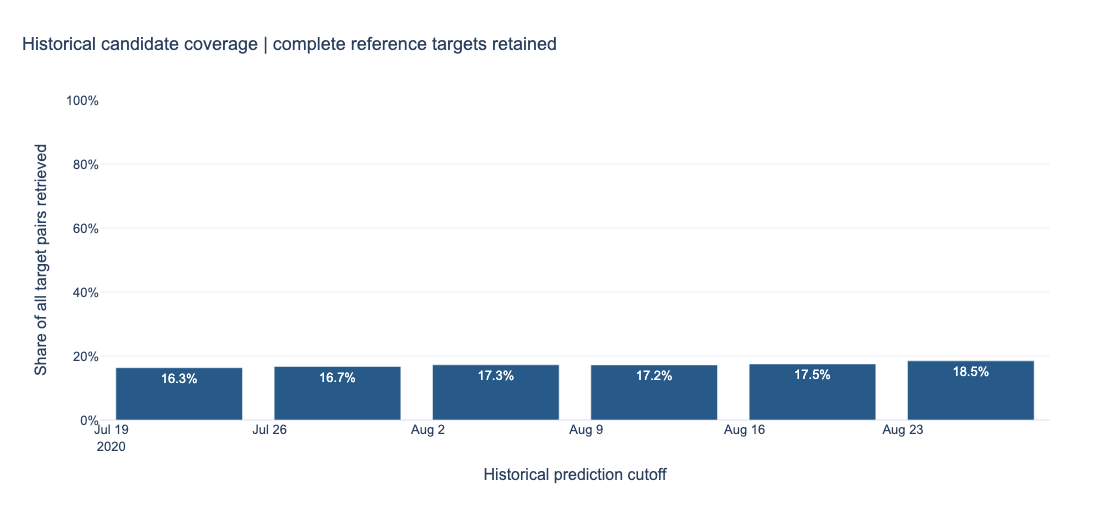

In [4]:
fig=px.bar(training_summary,x='cutoff',y='candidate_coverage',text_auto='.1%',
    labels={'cutoff':'Historical prediction cutoff','candidate_coverage':'Share of all target pairs retrieved'},
    title='Historical candidate coverage | complete reference targets retained')
fig.update_yaxes(tickformat='.0%',range=[0,1])
show_figure(fig,PROJECT_ROOT,'training_candidate_coverage')

## 5. Training-only eligibility and aligned inputs

For the binary relevance ranker, retain complete groups containing at least one positive and one negative candidate. Constant-label groups supply no within-group ordering signal for this fitting policy. This filter applies only to training, never to evaluation recipients or target references.

Sort by cutoff, customer ID and article ID. X contains only the declared ordered features; y contains labels; group sizes sum to the number of training rows. No within-group negative sampling or extra sample weighting is introduced.

,groups,candidate_rows,positive_rows
reason,,,
all_zero_labels,117467,35240100,0
has_positive_and_negative,2533,759900,3787


,cutoff,customer_id,group_size,positive_rows,row_end_exclusive,row_start
0,2020-07-22,0036a44bd648ce2dbc32688a465b9628b7a78395302f26...,300,1,300,0
1,2020-07-22,01344e5c48caf37aaf46b9fd8b624a22264722f589325e...,300,1,600,300
2,2020-07-22,016d8f0519d9e0572b3abebeab87408bad7a5c3a284016...,300,1,900,600
3,2020-07-22,01801532f13972c32a728870957d6c901e1f93bbc79985...,300,1,1200,900
4,2020-07-22,02a979988264eb07b6a1911484a3dfb383051419d2799b...,300,1,1500,1200


X_shape                   (759900, 31)
positive_training_rows            3787
informative_groups                2533
dtype: object

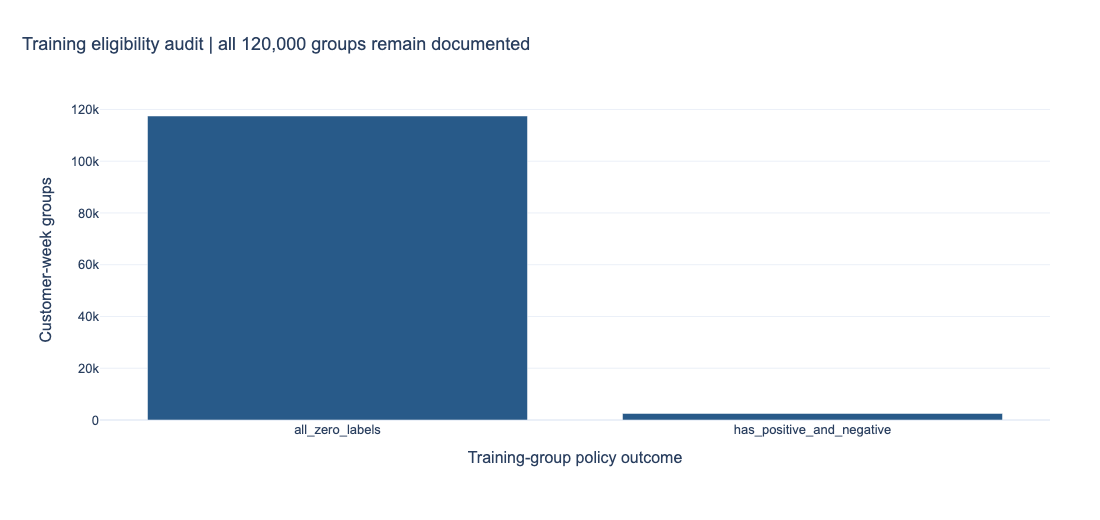

In [5]:
from atelier_ai.preparation import open_prepared
from atelier_ai.ranking_data import prepare_ranker_inputs
import duckdb
directory=PROJECT_ROOT/'data/processed/weekly_v1/training'
with duckdb.connect() as con:
    audit=con.execute('SELECT * FROM read_parquet(?)',[str(directory/'group_audit.parquet')]).df()
    rows=con.execute('SELECT * FROM read_parquet(?)',[str(directory/'rows.parquet')]).df()
inputs=prepare_ranker_inputs(rows,validation_cutoff=protocol['validation_start'])
assert inputs['groups'].sum()==len(inputs['X'])==len(inputs['y'])
display(audit.groupby('reason').agg(groups=('eligible','size'),candidate_rows=('candidate_rows','sum'),positive_rows=('positive_rows','sum')))
display(inputs['group_index'].head())
display(pd.Series({'X_shape':inputs['X'].shape,'positive_training_rows':int(inputs['y'].sum()),'informative_groups':len(inputs['groups'])}))
reason_counts=audit.groupby('reason').size().rename_axis('reason').reset_index(name='groups')
fig=px.bar(reason_counts,x='reason',y='groups',labels={'reason':'Training-group policy outcome','groups':'Customer-week groups'},title='Training eligibility audit | all 120,000 groups remain documented')
show_figure(fig,PROJECT_ROOT,'training_group_eligibility')

## Next step

Fit the planned initial LightGBM configuration and stop on full-reference validation NDCG@12. Hyperparameter comparisons, ablations, final refitting and V1 evaluation follow after this initial experiment.